# IMPORT LIBRARIES & LOAD DATASET

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,OrdinalEncoder
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler,MaxAbsScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
from tabulate import tabulate
from sklearn.model_selection import RandomizedSearchCV 

In [2]:
df=pd.read_csv(r"C:\Users\shaha\OneDrive\Documents\rainfall_datafile.csv")

In [3]:
df.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


In [4]:
df.describe()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
count,4188.000000,4184.000000,4185.000000,4182.000000,4184.000000,4185.000000,4183.000000,4181.000000,4184.000000,4182.000000,4181.000000,4177.000000,4178.000000,4162.000000,4182.000000,4179.000000,4178.000000,4175.000000
mean,1959.220630,18.938337,21.599427,27.412912,43.071845,85.660860,230.117475,347.020043,289.742185,197.316332,95.324707,39.496433,18.968645,1409.449207,40.522979,155.820914,1063.851580,153.648623
std,33.717097,33.793128,35.731734,46.927963,68.150985,122.695137,234.292087,268.850702,188.426071,135.547646,99.194851,68.358706,43.053759,902.599421,59.293904,201.198627,706.666045,166.863171
min,1901.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.400000,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000,62.300000,0.000000,0.000000,57.400000,0.000000
25%,1930.000000,0.600000,0.500000,1.000000,3.000000,8.600000,70.800000,175.600000,155.850000,100.400000,14.600000,0.600000,0.100000,803.025000,4.000000,24.000000,573.850000,34.000000
50%,1959.000000,5.950000,6.500000,7.900000,15.450000,36.900000,138.800000,285.000000,258.500000,173.700000,65.200000,9.400000,3.000000,1120.350000,18.900000,74.800000,880.600000,97.700000
75%,1988.000000,22.000000,26.600000,31.375000,49.650000,97.800000,305.000000,418.500000,377.625000,266.125000,148.300000,45.300000,17.500000,1643.575000,50.175000,196.950000,1287.450000,211.800000
max,2017.000000,583.700000,403.500000,605.600000,595.100000,1168.600000,1609.900000,2362.800000,1664.600000,1222.000000,948.300000,648.900000,617.500000,6331.100000,699.500000,1745.800000,4536.900000,1252.500000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4188 entries, 0 to 4187
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  4188 non-null   object 
 1   YEAR         4188 non-null   int64  
 2   JAN          4184 non-null   float64
 3   FEB          4185 non-null   float64
 4   MAR          4182 non-null   float64
 5   APR          4184 non-null   float64
 6   MAY          4185 non-null   float64
 7   JUN          4183 non-null   float64
 8   JUL          4181 non-null   float64
 9   AUG          4184 non-null   float64
 10  SEP          4182 non-null   float64
 11  OCT          4181 non-null   float64
 12  NOV          4177 non-null   float64
 13  DEC          4178 non-null   float64
 14  ANNUAL       4162 non-null   float64
 15  JF           4182 non-null   float64
 16  MAM          4179 non-null   float64
 17  JJAS         4178 non-null   float64
 18  OND          4175 non-null   float64
dtypes: flo

In [6]:
df.shape

(4188, 19)

In [7]:
datadict=pd.DataFrame(df.dtypes)
datadict["missingval"]=df.isnull().sum()
datadict["Nunique"]=df.nunique()
datadict["count"]=df.count()
datadict=datadict.rename(columns={0:"data type"})
datadict

,data type,missingval,Nunique,count
SUBDIVISION,object,0,36,4188
YEAR,int64,0,117,4188
JAN,float64,4,808,4184
FEB,float64,3,902,4185
MAR,float64,6,989,4182
APR,float64,4,1247,4184
MAY,float64,3,1751,4185
JUN,float64,5,2754,4183
JUL,float64,7,3093,4181
AUG,float64,4,2950,4184


### MISSING VALUE HANDLING

In [8]:
df.columns

Index(['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL',
       'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'JF', 'MAM', 'JJAS',
       'OND'],
      dtype='object')

In [9]:
df.isnull().sum()

SUBDIVISION     0
YEAR            0
JAN             4
FEB             3
MAR             6
APR             4
MAY             3
JUN             5
JUL             7
AUG             4
SEP             6
OCT             7
NOV            11
DEC            10
ANNUAL         26
JF              6
MAM             9
JJAS           10
OND            13
dtype: int64

In [10]:
for col in df.select_dtypes(include=['float']).columns:
    df[col].fillna(df[col].median(), inplace=True)

C:\Users\shaha\AppData\Local\Temp\ipykernel_2756\147489184.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


In [11]:
df.isnull().sum()

SUBDIVISION    0
YEAR           0
JAN            0
FEB            0
MAR            0
APR            0
MAY            0
JUN            0
JUL            0
AUG            0
SEP            0
OCT            0
NOV            0
DEC            0
ANNUAL         0
JF             0
MAM            0
JJAS           0
OND            0
dtype: int64

### OUTLIER HANDLING

<Axes: >

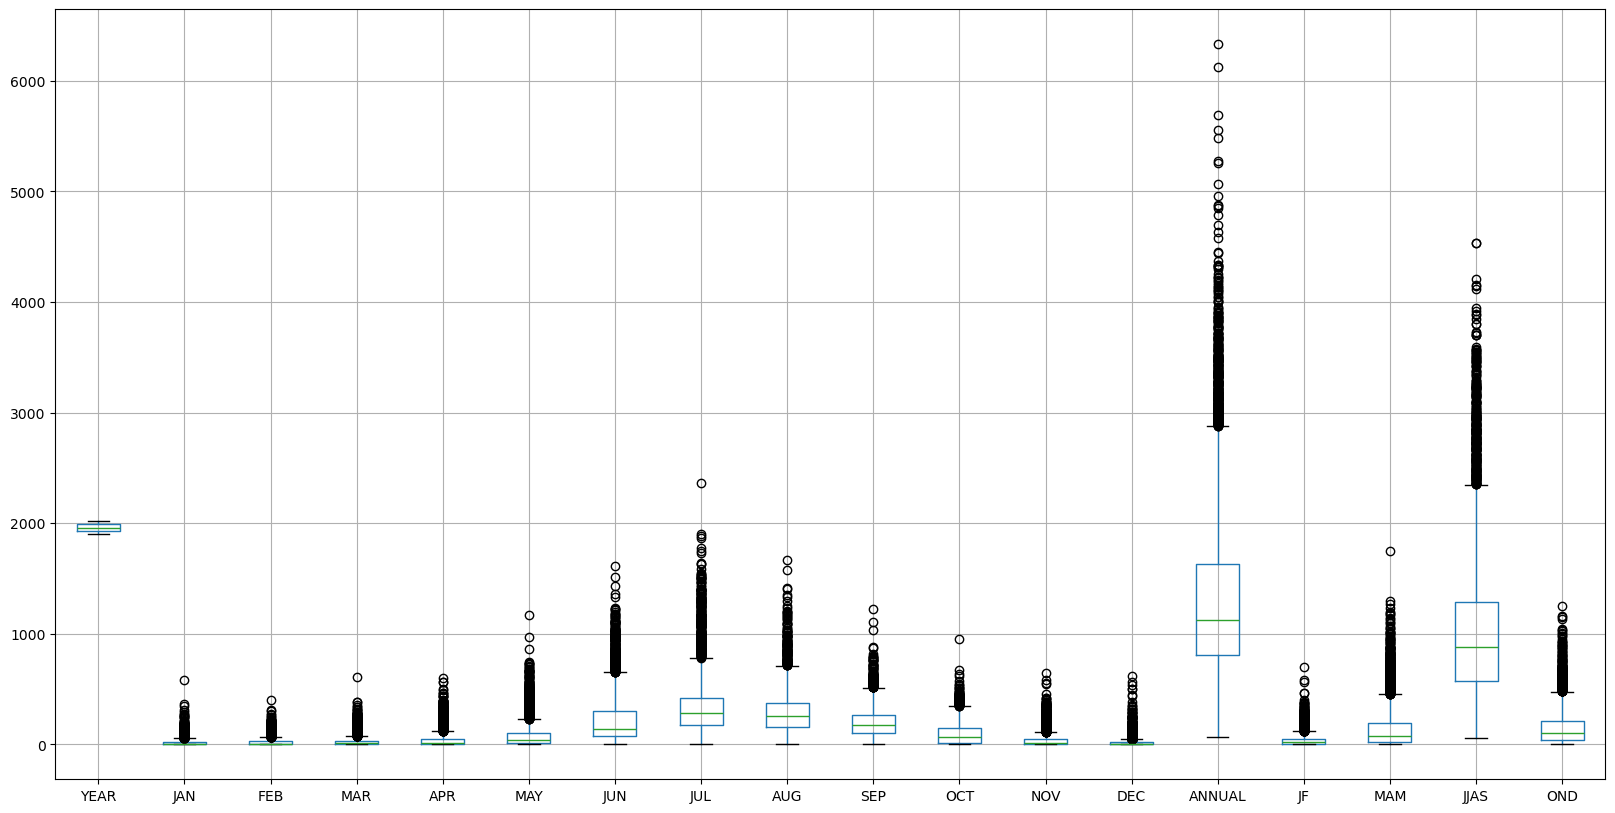

In [12]:
plt.figure(figsize=(20,10))
df.boxplot()

<Axes: >

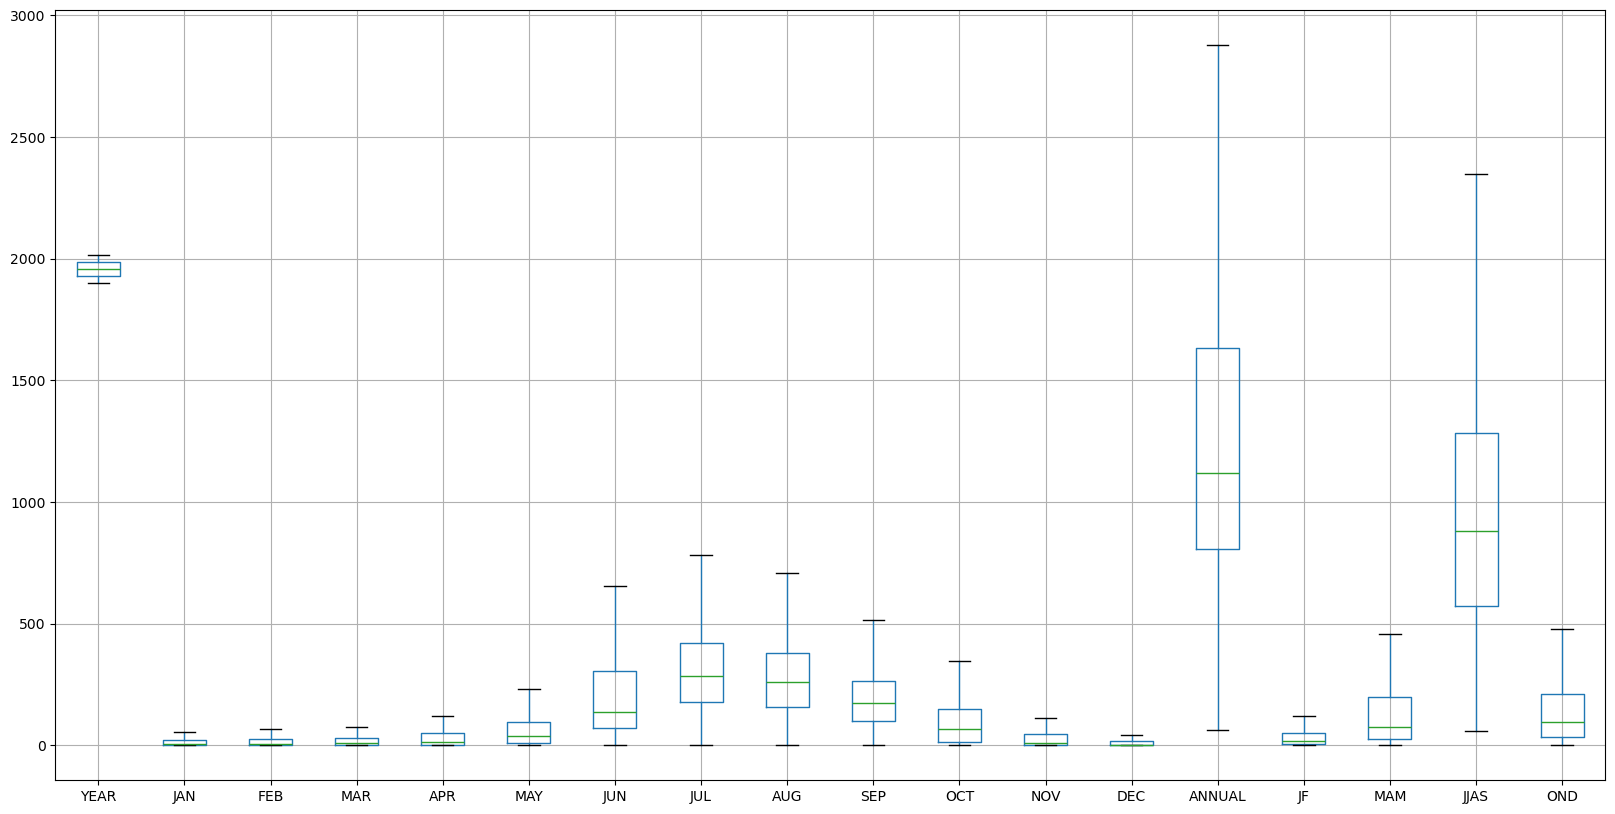

In [13]:
for i in df.select_dtypes(include='float').columns:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr
    df[i] = df[i].clip(lower, upper)
plt.figure(figsize=(20,10))
df.boxplot()

## DATA VISUALIZATION

### Distplot

C:\Users\shaha\AppData\Local\Temp\ipykernel_2756\2707030998.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['ANNUAL'], kde=True, bins=10)


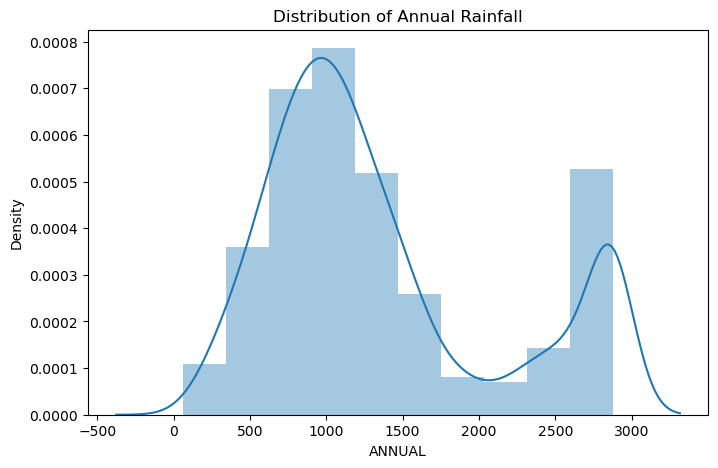

In [14]:
plt.figure(figsize=(8,5))
sns.distplot(df['ANNUAL'], kde=True, bins=10)
plt.title("Distribution of Annual Rainfall")
plt.show()

### Scatter Plot

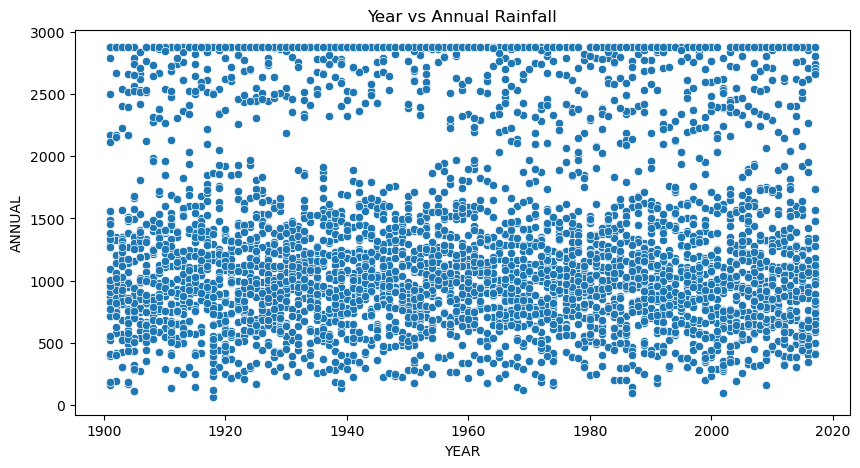

In [15]:
plt.figure(figsize=(10,5))
sns.scatterplot(x='YEAR', y='ANNUAL', data=df)
plt.title("Year vs Annual Rainfall")
plt.show()

### Line Plot

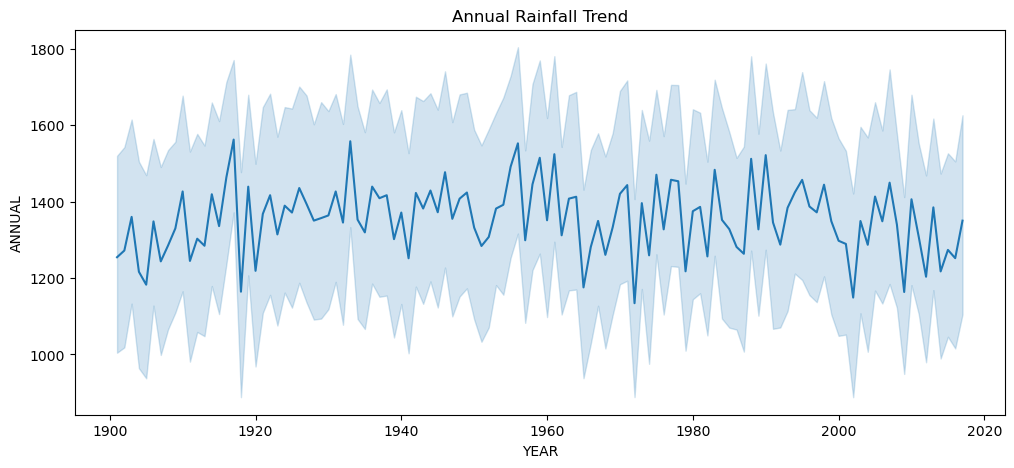

In [16]:
plt.figure(figsize=(12,5))
sns.lineplot(x='YEAR', y='ANNUAL', data=df)
plt.title("Annual Rainfall Trend")
plt.show()

### Bar Plot

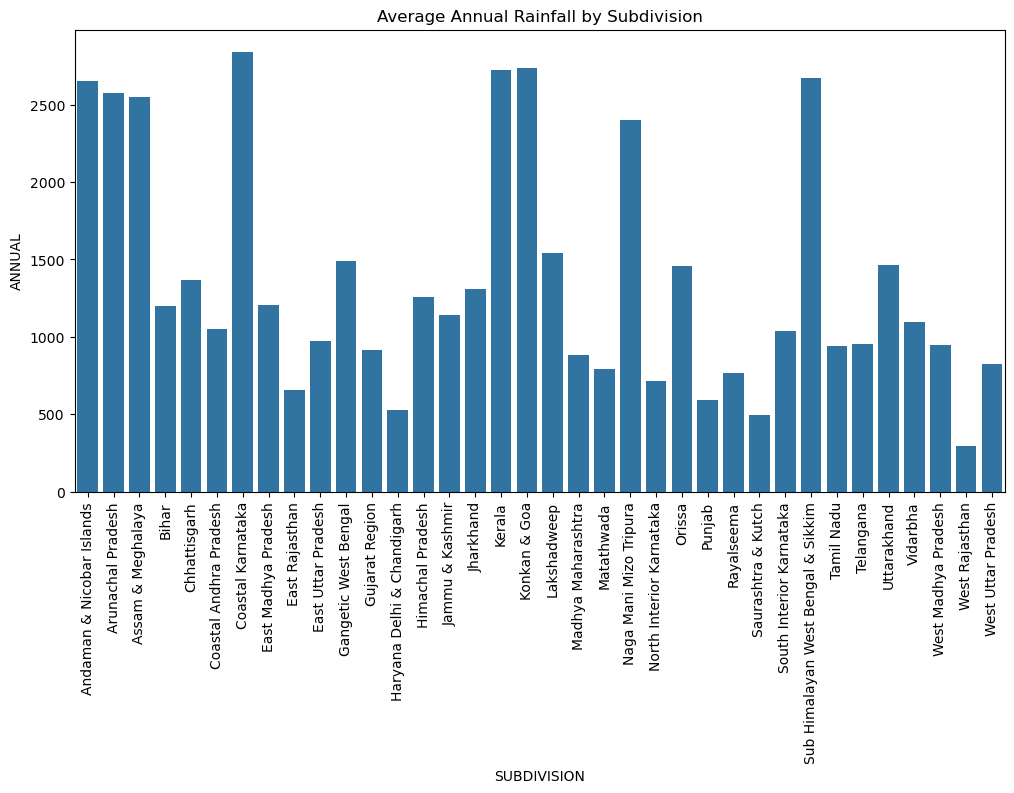

In [17]:
avg_rainfall = df.groupby('SUBDIVISION')['ANNUAL'].mean().reset_index()
plt.figure(figsize=(12,6))
sns.barplot(x='SUBDIVISION', y='ANNUAL', data=avg_rainfall)
plt.xticks(rotation=90)
plt.title("Average Annual Rainfall by Subdivision")
plt.show()

### Heatmap

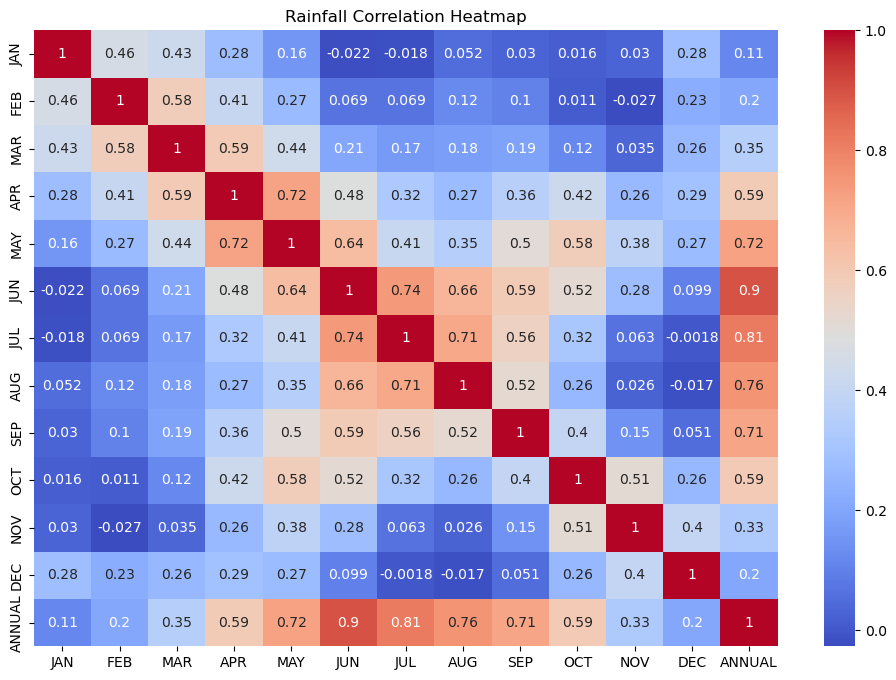

In [18]:
rain_cols = ['JAN','FEB','MAR','APR','MAY','JUN',
             'JUL','AUG','SEP','OCT','NOV','DEC',
             'ANNUAL']

plt.figure(figsize=(12,8))
sns.heatmap(df[rain_cols].corr(),
            annot=True,
            cmap='coolwarm')
plt.title("Rainfall Correlation Heatmap")
plt.show()

### Pie Chart

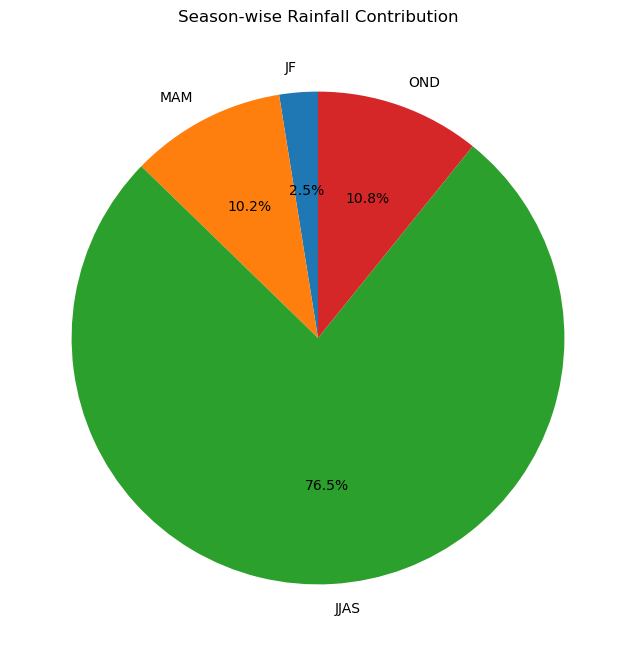

In [19]:
seasonal_rainfall = {
    'JF': df['JF'].mean(),
    'MAM': df['MAM'].mean(),
    'JJAS': df['JJAS'].mean(),
    'OND': df['OND'].mean()
}
plt.figure(figsize=(8,8))
plt.pie(
    seasonal_rainfall.values(),
    labels=seasonal_rainfall.keys(),
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Season-wise Rainfall Contribution')
plt.show()

## ENCODING

In [20]:
le=LabelEncoder()
df['SUBDIVISION']=le.fit_transform(df['SUBDIVISION'])

## SCALING

In [21]:
scaler=StandardScaler()

In [22]:
sc_cols=['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL',
       'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'JF', 'MAM', 'JJAS',
       'OND']

In [23]:
for i in sc_cols:
    df[i]=scaler.fit_transform(df[[i]])

# MODEL BUILDING

In [24]:
x=df.drop('ANNUAL',axis=1)

In [25]:
x

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,JF,MAM,JJAS,OND
0,-1.700725,-1.726945,1.938880,2.229996,0.329254,-0.785971,2.071476,1.551754,0.209196,1.210440,1.110538,2.742907,2.135296,1.436016,2.277136,2.174404,1.136555,2.406371
1,-1.700725,-1.697283,-0.804183,2.229996,-0.324492,-0.843619,2.071476,1.652537,-0.477116,2.605552,2.564583,1.116102,2.135296,2.083843,2.277136,2.174404,1.961393,2.406371
2,-1.700725,-1.667621,-0.096116,2.229996,-0.793652,-0.818555,2.071476,1.358415,2.039864,0.268777,1.161849,0.943896,2.135296,2.083843,2.277136,0.678877,1.435929,2.406371
3,-1.700725,-1.637959,-0.280102,-0.114600,-0.793652,2.146877,2.071476,1.436574,0.899035,-0.747291,2.564583,1.385173,2.135296,1.857104,-0.257357,2.174404,1.610466,2.406371
4,-1.700725,-1.608297,-0.731704,-0.789733,-0.666748,-0.169387,2.071476,2.123544,0.227336,0.291953,0.825121,1.799543,-0.101159,2.083843,-0.864676,1.179455,1.016266,2.406371
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4183,0.039474,1.595208,0.656554,0.790171,0.648436,-0.710778,0.241840,1.082290,-0.136983,-0.782055,-0.112907,-0.222797,1.266140,0.989016,0.714887,-0.035262,0.059514,0.240384
4184,0.039474,1.624870,2.161893,-0.050301,-0.624447,-0.470160,-0.153515,0.145933,-1.045515,1.118957,-0.496136,0.814742,0.770591,2.083843,0.946627,-0.405255,-0.106430,1.056844
4185,0.039474,1.654532,-0.681526,-0.766770,-0.651366,1.339490,0.815041,0.415888,-0.333000,-0.830846,-0.270047,0.773843,2.135296,2.083843,-0.827384,0.595901,-0.270859,2.406371
4186,0.039474,1.684195,2.212071,-0.234011,-0.670593,-0.778452,0.102378,0.541867,-0.307302,-1.197997,-0.949917,-0.375629,0.070077,2.083843,1.010556,-0.361046,-0.465444,0.152157


In [26]:
y=df['ANNUAL']

In [27]:
y

0       2877.275
1       2877.275
2       2877.275
3       2877.275
4       2566.700
          ...   
4183    1426.300
4184    1395.000
4185    1642.900
4186    1065.700
4187    1738.900
Name: ANNUAL, Length: 4188, dtype: float64

In [28]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [29]:
x_train.shape

(3350, 18)

## Linear Regression

In [30]:
model_lg=LinearRegression()

In [31]:
model_lg.fit(x_train,y_train)

LinearRegression()

In [32]:
y_pred_lg=model_lg.predict(x_test)

In [33]:
y_pred_lg

array([ 860.33683486,  649.10407419,  366.2624316 , 2537.2022386 ,
       1969.79063617, 2754.99974445, 2501.28481758, 1394.10350033,
       1171.7685091 ,  809.30375527,  203.74439065,  892.7490272 ,
        371.88112859, 1212.68642405, 2343.90833293,  842.68647016,
       2469.49994415,  947.43761652, 2299.95497478,  933.04681692,
        624.34723957,  551.60590775, 2917.76561777, 2507.25190981,
       2766.64782485,  336.37995338,  496.63398808, 1185.35596223,
        709.95779583,  486.44705042,  741.62791887, 1237.14177692,
       1414.48346296,  786.36608183,  826.04717519,  767.73852517,
       2558.13556708, 1317.28765306, 2838.27243898,  853.30231467,
       2825.52013759, 1275.93123553, 1046.59335014,  985.19354214,
        192.40126213, 1227.55050147, 1076.33104861, 1061.55062703,
        622.50179599, 1000.02318943,  270.09676909, 1005.60589591,
        653.44475157, 1342.76004232,  555.17784223, 1849.05925874,
       1061.86096912,  958.94388038, 1555.05041032, 1578.92071

In [34]:
r2_lg=r2_score(y_test,y_pred_lg)
mse_lg=mean_squared_error(y_test,y_pred_lg)
mae_lg=mean_absolute_error(y_test,y_pred_lg)

In [35]:
print("R2 SCORE:",r2_lg)
print("MEAN SQUARED ERROR:",mse_lg)
print("MEAN ABSOLUTE ERROR:",mae_lg)

R2 SCORE: 0.972057679901887
MEAN SQUARED ERROR: 18567.237360892304
MEAN ABSOLUTE ERROR: 61.27898363622992


## Random Forest

In [36]:
model_rf=RandomForestRegressor(n_estimators=100, random_state=42)

In [37]:
model_rf.fit(x_train,y_train)

RandomForestRegressor(random_state=42)

In [38]:
y_pred_rf=model_rf.predict(x_test)

In [39]:
r2_rf=r2_score(y_test,y_pred_rf)
mse_rf=mean_squared_error(y_test,y_pred_rf)
mae_rf=mean_absolute_error(y_test,y_pred_rf)

In [40]:
print("R2 SCORE:",r2_rf)
print("MEAN SQUARED ERROR:",mse_rf)
print("MEAN ABSOLUTE ERROR:",mae_rf)

R2 SCORE: 0.9797374805411488
MEAN SQUARED ERROR: 13464.129213364635
MEAN ABSOLUTE ERROR: 48.60186008353234


## Lightgbm

In [41]:
model=lgb.LGBMRegressor(verbose=0)

In [42]:
model.fit(x_train,y_train)

C:\Users\shaha\Downloads\ANACONDA\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\shaha\Downloads\ANACONDA\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\shaha\Downloads\ANACONDA\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\shaha\Downloads\ANACONDA\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~

LGBMRegressor(verbose=0)

In [43]:
y_pred_lgb=model.predict(x_test)

In [44]:
r2_lgb=r2_score(y_test,y_pred_lgb)
mse_lgb=mean_squared_error(y_test,y_pred_lgb)
mae_lgb=mean_absolute_error(y_test,y_pred_lgb)

In [45]:
print("R2 SCORE:",r2_lgb)
print("MEAN SQUARED ERROR:",mse_lgb)
print("MEAN ABSOLUTE ERROR:",mae_lgb)

R2 SCORE: 0.98233283872364
MEAN SQUARED ERROR: 11739.55404417169
MEAN ABSOLUTE ERROR: 43.92492456236944


## TABULATE

In [46]:
table=[["MODEL","R2","MSE","MAE"],['Linear Regression',r2_lg,mse_lg,mae_lg],['Random Forest',r2_rf,mse_rf,mae_rf],['LightGBM',r2_lgb,mse_lgb,mae_lgb]]

In [47]:
print(tabulate(table,headers='firstrow',tablefmt='fancy_grid'))

╒═══════════════════╤══════════╤═════════╤═════════╕
│ MODEL             │       R2 │     MSE │     MAE │
╞═══════════════════╪══════════╪═════════╪═════════╡
│ Linear Regression │ 0.972058 │ 18567.2 │ 61.279  │
├───────────────────┼──────────┼─────────┼─────────┤
│ Random Forest     │ 0.979737 │ 13464.1 │ 48.6019 │
├───────────────────┼──────────┼─────────┼─────────┤
│ LightGBM          │ 0.982333 │ 11739.6 │ 43.9249 │
╘═══════════════════╧══════════╧═════════╧═════════╛


## HYPERPARAMETER TUNING

## RandomizedSearchCV

In [48]:
import lightgbm as lgb
model=lgb.LGBMRegressor(verbose=0)

In [49]:
param_grid = {
    'n_estimators': [200, 500],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [31, 50, 100],
    'max_depth': [-1, 5, 10],
    'min_child_samples': [20, 50],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [50]:
random_search = RandomizedSearchCV(model, param_distributions=param_grid,cv=5,verbose=0) 

In [51]:
random_search.fit(x_train, y_train)

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

RandomizedSearchCV(cv=5, estimator=LGBMRegressor(verbose=0),
                   param_distributions={'colsample_bytree': [0.8, 1.0],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [-1, 5, 10],
                                        'min_child_samples': [20, 50],
                                        'n_estimators': [200, 500],
                                        'num_leaves': [31, 50, 100],
                                        'subsample': [0.8, 1.0]})

In [52]:
print("Best Parameters:",random_search.best_params_)

Best Parameters: {'subsample': 0.8, 'num_leaves': 50, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


In [53]:
print("Best Score (Accuracy):", random_search.best_score_) 

Best Score (Accuracy): 0.9867115122546192


# FINAL MODEL

In [54]:
final_model=lgb.LGBMRegressor(num_leaves=5,n_estimators=100,learning_rate=0.05)

In [55]:
final_model.fit(x_train,y_train)

LGBMRegressor(learning_rate=0.05, num_leaves=5)

In [56]:
final_pred=final_model.predict(x_test)

In [57]:
final_pred

array([ 964.20381625,  668.51445884,  475.98597314, 2527.12556775,
       1989.42267237, 2831.57567543, 2601.00134272, 1448.71084174,
       1148.89254356,  791.85551289,  287.18814086,  897.18510263,
        378.04637914, 1135.5802102 , 2411.32059755,  875.75287277,
       2809.74503898,  995.91023083, 2441.77275137,  989.04675947,
        629.61594056,  535.27631036, 2804.63113171, 2716.11792371,
       2834.46996137,  357.63412696,  507.80030572, 1176.02322574,
        709.23866176,  524.59805633,  765.0018251 , 1183.21376451,
       1308.84963942,  734.91305678,  813.09607834,  761.93542191,
       2755.55778803, 1247.65645011, 2842.88746454,  864.7107329 ,
       2829.13560248, 1291.75826211, 1102.2065192 , 1057.91621279,
        287.18814086, 1115.87671148, 1057.17595462, 1070.35316583,
        666.8091282 ,  965.65726719,  305.3532018 ,  968.83905269,
        678.25493116, 1348.408462  ,  560.6475723 , 1719.52055687,
       1048.39802609, 1027.54082838, 1426.97562466, 1664.33889

In [58]:
final_r2=r2_score(y_test,final_pred)

In [59]:
final_r2

0.973017321543134

# PREDICTION

In [60]:
x

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,JF,MAM,JJAS,OND
0,-1.700725,-1.726945,1.938880,2.229996,0.329254,-0.785971,2.071476,1.551754,0.209196,1.210440,1.110538,2.742907,2.135296,1.436016,2.277136,2.174404,1.136555,2.406371
1,-1.700725,-1.697283,-0.804183,2.229996,-0.324492,-0.843619,2.071476,1.652537,-0.477116,2.605552,2.564583,1.116102,2.135296,2.083843,2.277136,2.174404,1.961393,2.406371
2,-1.700725,-1.667621,-0.096116,2.229996,-0.793652,-0.818555,2.071476,1.358415,2.039864,0.268777,1.161849,0.943896,2.135296,2.083843,2.277136,0.678877,1.435929,2.406371
3,-1.700725,-1.637959,-0.280102,-0.114600,-0.793652,2.146877,2.071476,1.436574,0.899035,-0.747291,2.564583,1.385173,2.135296,1.857104,-0.257357,2.174404,1.610466,2.406371
4,-1.700725,-1.608297,-0.731704,-0.789733,-0.666748,-0.169387,2.071476,2.123544,0.227336,0.291953,0.825121,1.799543,-0.101159,2.083843,-0.864676,1.179455,1.016266,2.406371
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4183,0.039474,1.595208,0.656554,0.790171,0.648436,-0.710778,0.241840,1.082290,-0.136983,-0.782055,-0.112907,-0.222797,1.266140,0.989016,0.714887,-0.035262,0.059514,0.240384
4184,0.039474,1.624870,2.161893,-0.050301,-0.624447,-0.470160,-0.153515,0.145933,-1.045515,1.118957,-0.496136,0.814742,0.770591,2.083843,0.946627,-0.405255,-0.106430,1.056844
4185,0.039474,1.654532,-0.681526,-0.766770,-0.651366,1.339490,0.815041,0.415888,-0.333000,-0.830846,-0.270047,0.773843,2.135296,2.083843,-0.827384,0.595901,-0.270859,2.406371
4186,0.039474,1.684195,2.212071,-0.234011,-0.670593,-0.778452,0.102378,0.541867,-0.307302,-1.197997,-0.949917,-0.375629,0.070077,2.083843,1.010556,-0.361046,-0.465444,0.152157


In [61]:
new=x.head(1)

In [62]:
model.fit(x_train, y_train)

LGBMRegressor(verbose=0)

In [63]:
prediction=model.predict(new)
prediction

array([2919.06587306])

In [64]:
y

0       2877.275
1       2877.275
2       2877.275
3       2877.275
4       2566.700
          ...   
4183    1426.300
4184    1395.000
4185    1642.900
4186    1065.700
4187    1738.900
Name: ANNUAL, Length: 4188, dtype: float64